In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!pip -q install -U ultralytics h5py
import ultralytics

print("ultralytics version:", ultralytics.__version__)

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 460.8 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 31.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 10.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow 2.21.0 requires h5py<3.15.0,>=3.11.0, but you have h5py 3.16.0 which is incompatible.
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
ultralytics version: 8.4.183


In [ ]:
!nvidia-smi

Sun Nov  1 06:30:39 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!pip list | grep -E "torch|torchvision|ultralytics|numpy|opencv|rasterio|segmentation-models"

numpy                                 2.1.3
opencv-contrib-python                 4.14.0.94
opencv-python                         5.0.0.93
opencv-python-headless                5.0.0.93
rasterio                              1.5.2
torch                                 2.11.0+cu130
torchao                               0.10.0
torchaudio                            2.11.0+cu130
torchcodec                            0.11.0+cu130
torchdata                             0.11.0
torchsummary                          1.5.1
torchtune                             0.6.1
torchvision                           0.26.0+cu130


In [ ]:
#YOLO11 can perform landslide segmentation using satellite images with multiple input channels.(LANDSLIDE4SENSE)

import os, glob, re, json, random, time, shutil
import numpy as np, cv2, h5py
import matplotlib.pyplot as plt
import pandas as pd
from tqdm.auto import tqdm

# ---- paths ----
PH3  = '/content/drive/MyDrive/TerraSeg/phase3'    # split from Phase 3
OUT  = '/content/drive/MyDrive/TerraSeg/phase6'    # results of this notebook (on Drive)
ROOT = '/content/yolo_l4s'                         # converted dataset (local disk, rebuilt each session)
os.makedirs(OUT, exist_ok=True); os.makedirs(f'{OUT}/runs', exist_ok=True)

# ---- settings ----
IMGSZ = 256            # patches are 128x128; YOLO upscales them (small landslides need bigger feature maps)
MODEL = 'yolo11s-seg.pt'   # n = smaller/faster, s = good start, m = bigger
SEEDS = [42]           # later: [42, 123, 777]
FORCE = False          # True = retrain even if weights exist

# every variant = a list of channel numbers. Channels 0-11 = Sentinel-2 bands B1..B12, 12 = slope, 13 = DEM.
# RGB = B4,B3,B2 = channels 3,2,1  (the same choice as in Phase 2A / Phase 5)
VARIANTS = {
    'rgb':       [3, 2, 1],
    'rgb_slope': [3, 2, 1, 12],
    'ch14':      list(range(14)),
}
print("variants:", {k: len(v) for k, v in VARIANTS.items()})

variants: {'rgb': 3, 'rgb_slope': 4, 'ch14': 14}


In [ ]:
from huggingface_hub import snapshot_download
snapshot_download(repo_id="ibm-nasa-geospatial/Landslide4sense", repo_type="dataset",
                  allow_patterns=["*train*"], local_dir="/content/l4s", max_workers=8)

def num(p): return int(re.findall(r'(\d+)\.h5$', p)[0])
img_files  = sorted(glob.glob('/content/l4s/images/train/image_*.h5'), key=num)
mask_files = sorted(glob.glob('/content/l4s/annotations/train/mask_*.h5'), key=num)
assert len(img_files) == len(mask_files) > 0
assert all(num(a) == num(b) for a, b in zip(img_files, mask_files)), "image/mask mismatch"
def first(h): return h[list(h.keys())[0]][:]

def load_patch(i):
    with h5py.File(img_files[i]) as h: x = np.nan_to_num(first(h)).astype(np.float32).transpose(2, 0, 1)   # (14,128,128)
    with h5py.File(mask_files[i]) as h: m = (first(h) > 0.5).astype(np.uint8)                              # (128,128)
    return x, m

sp = np.load(f'{PH3}/split.npz')
SPLITS = {'train': sp['train'], 'val': sp['val'], 'test': sp['test']}
print({k: len(v) for k, v in SPLITS.items()}, "| total files:", len(img_files))

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7603 files:   0%|          | 0/7603 [00:00<?, ?it/s]

{'train': 2659, 'val': 569, 'test': 571} | total files: 3799


In [ ]:
rng = np.random.RandomState(0)
sample = rng.choice(SPLITS['train'], size=min(600, len(SPLITS['train'])), replace=False)
vals = [[] for _ in range(14)]
for i in tqdm(sample):
    x, _ = load_patch(i)
    for c in range(14):
        vals[c].append(x[c, ::2, ::2].ravel())
LO = np.array([np.percentile(np.concatenate(v), 1) for v in vals], np.float32)
HI = np.array([np.percentile(np.concatenate(v), 99) for v in vals], np.float32)
json.dump({'lo': LO.tolist(), 'hi': HI.tolist()}, open(f'{OUT}/uint8_scaling.json', 'w'))
print("lo:", np.round(LO, 3))
print("hi:", np.round(HI, 3))

def to_uint8(x):
    # x: (14,H,W) float -> (14,H,W) uint8 using the training percentiles
    q = np.clip((x - LO.reshape(-1, 1, 1)) / (HI - LO + 1e-6).reshape(-1, 1, 1), 0, 1)
    return np.round(q * 255).astype(np.uint8)

  0%|          | 0/600 [00:00<?, ?it/s]

lo: [      0.712       0.638       0.491       0.391       0.257       0.121       0.089        0.07       0.068       0.553       0.033       0.042           0       0.031]
hi: [       1.36       1.723       2.042       3.161       2.302       1.912       1.986       2.058       2.283       4.531       2.266       3.066       2.809       4.359]


In [ ]:
MIN_AREA = 6.0     # contour area in pixels^2 (a 4x4 blob has area 9)

def mask_to_yolo_lines(mask, min_area=MIN_AREA):
    h, w = mask.shape
    cnts, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    lines = []
    for c in cnts:
        if len(c) < 3 or cv2.contourArea(c) < min_area:
            continue
        pts = c.reshape(-1, 2).astype(np.float64)
        pts[:, 0] /= w; pts[:, 1] /= h
        lines.append('0 ' + ' '.join(f'{v:.5f}' for v in pts.ravel()))
    return lines

def read_tiff_like_ultralytics(path):
    # the same steps Ultralytics uses to read multi-band TIFFs
    ok, frames = cv2.imdecodemulti(np.fromfile(path, np.uint8), cv2.IMREAD_UNCHANGED)
    assert ok, f"cannot read {path}"
    return np.stack(frames, axis=2)                  # (H, W, C)

# quick self-test on a synthetic patch before touching real data
_m = np.zeros((128, 128), np.uint8); _m[20:50, 30:70] = 1; _m[90:93, 90:93] = 1
print("self-test: label lines =", len(mask_to_yolo_lines(_m)), "(expect 1: the 3x3 blob is dropped)")
_x = (np.random.rand(14, 128, 128) * 255).astype(np.uint8)
cv2.imwritemulti('/tmp/_t.tiff', [_x[c] for c in range(14)])
_r = read_tiff_like_ultralytics('/tmp/_t.tiff')
print("self-test: tiff round trip shape", _r.shape, "| identical:", np.array_equal(_r.transpose(2, 0, 1), _x))

self-test: label lines = 1 (expect 1: the 3x3 blob is dropped)
self-test: tiff round trip shape (128, 128, 14) | identical: True


In [ ]:
shutil.rmtree(ROOT, ignore_errors=True)
for v in VARIANTS:
    for s in SPLITS:
        os.makedirs(f'{ROOT}/{v}/images/{s}', exist_ok=True)
        os.makedirs(f'{ROOT}/{v}/labels/{s}', exist_ok=True)
for s in SPLITS:
    os.makedirs(f'{ROOT}/gt/{s}', exist_ok=True)

inst_counts, inst_areas, empty_labels = [], [], 0
for s, idxs in SPLITS.items():
    for i in tqdm(idxs, desc=s):
        x, m = load_patch(i)
        u8 = to_uint8(x)
        name = f'p{int(i):05d}'
        lines = mask_to_yolo_lines(m)
        for v, chans in VARIANTS.items():
            ok = cv2.imwritemulti(f'{ROOT}/{v}/images/{s}/{name}.tiff', [u8[c] for c in chans])
            assert ok, f"failed to write {name}"
            open(f'{ROOT}/{v}/labels/{s}/{name}.txt', 'w').write('\n'.join(lines))
        cv2.imwrite(f'{ROOT}/gt/{s}/{name}.png', m * 255)
        inst_counts.append(len(lines)); empty_labels += (len(lines) == 0)
        for c in cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0]:
            inst_areas.append(cv2.contourArea(c))

print(f"patches: {len(inst_counts)} | objects: {sum(inst_counts)} | patches with no object: {empty_labels}")
print(f"objects per patch: mean {np.mean(inst_counts):.2f}, max {max(inst_counts)}")
print(f"object contour area (px^2): median {np.median(inst_areas):.0f}, 10th pct {np.percentile(inst_areas, 10):.0f}, 90th pct {np.percentile(inst_areas, 90):.0f}")

def write_yaml(variant):
    nch = len(VARIANTS[variant])
    txt = (f"path: {ROOT}/{variant}\ntrain: images/train\nval: images/val\ntest: images/test\n"
           f"channels: {nch}\nnames:\n  0: landslide\n")
    open(f'{ROOT}/{variant}/data.yaml', 'w').write(txt)
for v in VARIANTS:
    write_yaml(v)
print(open(f'{ROOT}/ch14/data.yaml').read())

train:   0%|          | 0/2659 [00:00<?, ?it/s]

val:   0%|          | 0/569 [00:00<?, ?it/s]

test:   0%|          | 0/571 [00:00<?, ?it/s]

patches: 3799 | objects: 9957 | patches with no object: 1655
objects per patch: mean 2.62, max 52
object contour area (px^2): median 20, 10th pct 0, 90th pct 187
path: /content/yolo_l4s/ch14
train: images/train
val: images/val
test: images/test
channels: 14
names:
  0: landslide



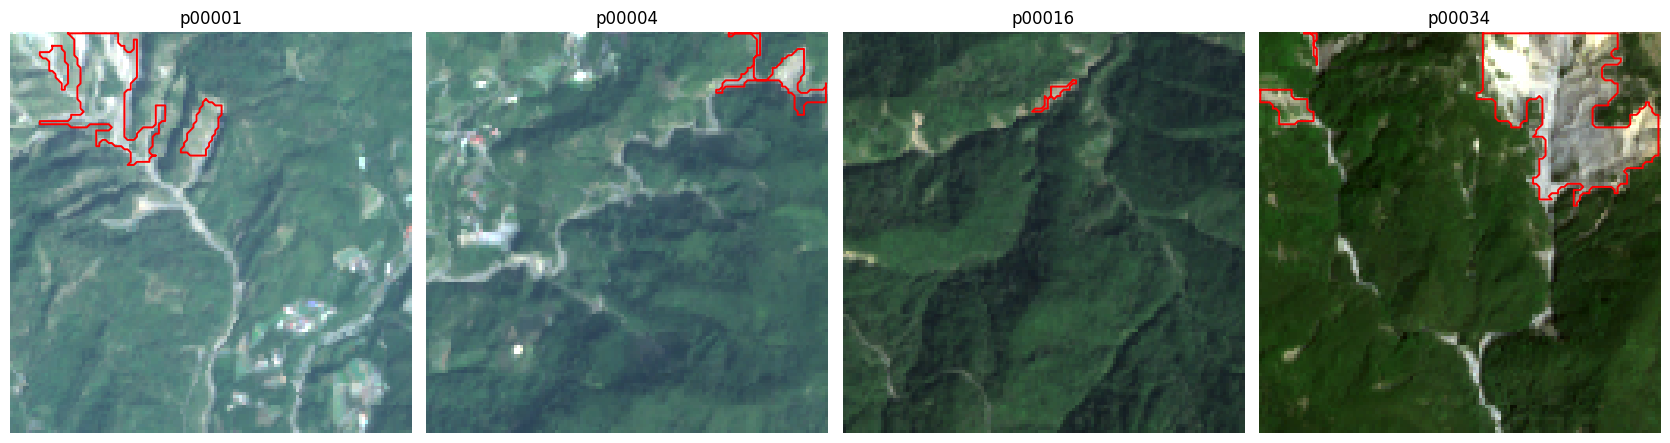

14-channel TIFF read back OK: (128, 128, 14) uint8


In [ ]:
test_names = sorted(os.path.basename(p)[:-5] for p in glob.glob(f'{ROOT}/ch14/images/test/*.tiff'))
pick = [n for n in test_names if open(f'{ROOT}/ch14/labels/test/{n}.txt').read().strip()][:4]

fig, ax = plt.subplots(1, len(pick), figsize=(4.2 * len(pick), 4.4))
for a, n in zip(np.atleast_1d(ax), pick):
    arr = read_tiff_like_ultralytics(f'{ROOT}/ch14/images/test/{n}.tiff')        # (128,128,14)
    assert arr.shape == (128, 128, 14) and arr.dtype == np.uint8, arr.shape
    a.imshow(arr[:, :, [3, 2, 1]])
    for line in open(f'{ROOT}/ch14/labels/test/{n}.txt').read().strip().split('\n'):
        p = np.array(line.split()[1:], float).reshape(-1, 2) * 128
        a.plot(np.r_[p[:, 0], p[0, 0]], np.r_[p[:, 1], p[0, 1]], color='red', linewidth=1.4)
    a.set_title(n); a.axis('off')
plt.tight_layout(); plt.show()
print("14-channel TIFF read back OK:", arr.shape, arr.dtype)

In [ ]:
from ultralytics import YOLO
arch = YOLO('yolo11s-seg.yaml')
names = [type(layer).__name__ for layer in arch.model.model]
print(names)
for need in ('C3k2', 'C2PSA', 'Segment'):
    assert need in names, f"{need} not found in this architecture"
print("OK: contains C3k2, C2PSA and the Segment head")
print("parameters (M):", round(sum(p.numel() for p in arch.model.parameters()) / 1e6, 2))
del arch

['Conv', 'Conv', 'C3k2', 'Conv', 'C3k2', 'Conv', 'C3k2', 'Conv', 'C3k2', 'SPPF', 'C2PSA', 'Upsample', 'Concat', 'C3k2', 'Upsample', 'Concat', 'C3k2', 'Conv', 'Concat', 'C3k2', 'Conv', 'Concat', 'C3k2', 'Segment']
OK: contains C3k2, C2PSA and the Segment head
parameters (M): 10.11


In [ ]:
def train_yolo(variant, seed, epochs=100):
    run = f'{variant}_s{seed}'
    run_dir = f'{OUT}/runs/{run}'
    best, last = f'{run_dir}/weights/best.pt', f'{run_dir}/weights/last.pt'
    if os.path.exists(best) and not FORCE and epochs >= 50:
        print(f"[{run}] best.pt exists - skipping training")
        return best
    if os.path.exists(last) and not FORCE and epochs >= 50:
        print(f"[{run}] resuming from last.pt")
        YOLO(last).train(resume=True)
        return best
    model = YOLO(MODEL)
    model.train(
        data=f'{ROOT}/{variant}/data.yaml', epochs=epochs, imgsz=IMGSZ, batch=32, seed=seed,
        optimizer='AdamW', lr0=1e-3, weight_decay=1e-4, cos_lr=True, patience=25,
        hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, fliplr=0.5, flipud=0.5, degrees=0.0,
        mosaic=1.0, mixup=0.0, close_mosaic=10,
        project=f'{OUT}/runs', name=run, exist_ok=True, workers=2, plots=True,
    )
    return best

print("ready")

ready


In [ ]:
QUICK = True
if QUICK:
    train_yolo('rgb', seed=0, epochs=3)
    # also test the 14-channel path, because that is where problems would appear
    train_yolo('ch14', seed=0, epochs=3)
    print("Quick tests finished without errors -> now set QUICK = False and run D3.")

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/yolo_l4s/rgb/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=256, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=rgb_s0, nbs=64, nms=None, opset=None, optimize=False, opti

In [ ]:
for seed in SEEDS:
    for variant in VARIANTS:
        print("=" * 70, f"\n{variant} | seed {seed}\n", "=" * 70, sep="")
        train_yolo(variant, seed, epochs=100)
print("All training finished.")

rgb | seed 42
[rgb_s42] best.pt exists - skipping training
rgb_slope | seed 42
[rgb_slope_s42] best.pt exists - skipping training
ch14 | seed 42
[ch14_s42] best.pt exists - skipping training
All training finished.


In [ ]:
from scipy.ndimage import binary_erosion, distance_transform_edt

def boundary(m): return m & ~binary_erosion(m, border_value=0)

def boundary_f1(pred, gt, tol=2):
    bp, bg = boundary(pred), boundary(gt)
    if bg.sum() == 0 and bp.sum() == 0: return None
    if bg.sum() == 0 or bp.sum() == 0: return 0.0
    dg, dp = distance_transform_edt(~bg), distance_transform_edt(~bp)
    p, r = (dg[bp] <= tol).mean(), (dp[bg] <= tol).mean()
    return 0.0 if p + r == 0 else float(2 * p * r / (p + r))

def pixel_metrics(preds, gts):
    tp = fp = fn = 0.0; bfs = []
    for p, g in zip(preds, gts):
        tp += (p & g).sum(); fp += (p & ~g).sum(); fn += (~p & g).sum()
        if g.any():
            b = boundary_f1(p, g)
            if b is not None: bfs.append(b)
    e = 1e-9
    P, R = tp / (tp + fp + e), tp / (tp + fn + e)
    return {'IoU': tp / (tp + fp + fn + e), 'F1': 2 * P * R / (P + R + e), 'Precision': P, 'Recall': R,
            'Boundary F1': float(np.mean(bfs)) if bfs else 0.0}

def load_gts(split, names):
    return [cv2.imread(f'{ROOT}/gt/{split}/{n}.png', 0) > 127 for n in names]
def predict_instances(model, variant, split, conf_min=0.05):
    files = sorted(
        glob.glob(f'{ROOT}/{variant}/images/{split}/*.tiff')
    )

    names = [os.path.basename(f)[:-5] for f in files]
    expected_channels = len(VARIANTS[variant])
    out = []

    import torch

    batch_size = 16

    for start in tqdm(
        range(0, len(files), batch_size),
        desc=f'{variant} {split}'
    ):
        batch_files = files[start:start + batch_size]
        batch_images = []

        for path in batch_files:
            img = read_tiff_like_ultralytics(path)

            assert img.ndim == 3, (
                f'Unexpected image shape: {img.shape}'
            )

            assert img.shape[2] == expected_channels, (
                f'{path}: expected {expected_channels} channels, '
                f'got {img.shape[2]}'
            )

            img = np.ascontiguousarray(
                img.transpose(2, 0, 1)
            )

            batch_images.append(img)

        batch = np.stack(batch_images, axis=0)
        batch = torch.from_numpy(batch).float() / 255.0

        results = model.predict(
            source=batch,
            imgsz=IMGSZ,
            conf=conf_min,
            iou=0.7,
            max_det=100,
            verbose=False
        )

        for r in results:
            polys, scores, boxes = [], [], []

            if r.masks is not None and len(r.masks.xy) > 0:
                for poly, sc, bx in zip(
                    r.masks.xy,
                    r.boxes.conf.cpu().numpy(),
                    r.boxes.xyxy.cpu().numpy()
                ):
                    if len(poly) >= 3:
                        polys.append(poly)
                        scores.append(float(sc))
                        boxes.append(bx)

            out.append({
                'polys': polys,
                'scores': scores,
                'boxes': boxes
            })

    assert len(out) == len(names), (
        f'Expected {len(names)} predictions, got {len(out)}'
    )

    return names, out


def render(cache, thr, size=128):
    maps = []
    for item in cache:
        m = np.zeros((size, size), np.uint8)
        for poly, sc in zip(item['polys'], item['scores']):
            if sc >= thr:
                cv2.fillPoly(m, [np.round(poly).astype(np.int32)], 1)
        maps.append(m.astype(bool))
    return maps

# self-test: a label polygon painted back should reproduce the mask it came from
_lines = mask_to_yolo_lines(_m)
_poly = np.array(_lines[0].split()[1:], float).reshape(-1, 2) * 128
_back = render([{'polys': [_poly], 'scores': [0.9]}], 0.5)[0]
print("self-test IoU of polygon round trip:", round(float((_back & (_m == 1)).sum() / (_back | (_m == 1)).sum()), 3), "(expect close to 1; the 3x3 blob is intentionally absent)")

self-test IoU of polygon round trip: 0.993 (expect close to 1; the 3x3 blob is intentionally absent)


In [ ]:
run = 'rgb_slope_s42'

model = YOLO(
    f'{OUT}/runs/{run}/weights/best.pt'
)

names, cache = predict_instances(
    model,
    'rgb_slope',
    'val'
)

print('Validation images:', len(names))
print('Predictions:', len(cache))

rgb_slope val:   0%|          | 0/36 [00:00<?, ?it/s]

Validation images: 569
Predictions: 569


In [ ]:
def evaluate_yolo(variant, seed):
    run = f'{variant}_s{seed}'
    best = f'{OUT}/runs/{run}/weights/best.pt'
    model = YOLO(best)

    # 1) YOLO's own metrics on the test split
    m = model.val(data=f'{ROOT}/{variant}/data.yaml', split='test', imgsz=IMGSZ, batch=32,
                  verbose=False, plots=False, project=f'{OUT}/runs', name=f'{run}_test', exist_ok=True)
    sp = m.speed
    ms = sp['preprocess'] + sp['inference'] + sp['postprocess']

    # 2) pixel metrics: pick the confidence on VAL, report on TEST
    names_v, cache_v = predict_instances(model, variant, 'val')
    gts_v = load_gts('val', names_v)
    thrs = np.round(np.arange(0.05, 0.80, 0.05), 2)
    val_iou = [pixel_metrics(render(cache_v, t), gts_v)['IoU'] for t in thrs]
    best_thr = float(thrs[int(np.argmax(val_iou))])

    names_t, cache_t = predict_instances(model, variant, 'test')
    gts_t = load_gts('test', names_t)
    pm = pixel_metrics(render(cache_t, best_thr), gts_t)

    row = {'variant': variant, 'seed': seed, 'conf': best_thr, **{k: round(v, 4) for k, v in pm.items()},
           'mask mAP50': round(float(m.seg.map50), 4), 'mask mAP50-95': round(float(m.seg.map), 4),
           'box mAP50': round(float(m.box.map50), 4), 'ms/img': round(ms, 2), 'FPS': round(1000 / ms, 1)}
    return row, (names_t, cache_t, best_thr)

rows, caches = [], {}
for seed in SEEDS:
    for variant in VARIANTS:
        row, cache = evaluate_yolo(variant, seed)
        rows.append(row); caches[(variant, seed)] = cache
        print(row)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s-seg summary (fused): 113 layers, 10,067,203 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1616.7±573.7 MB/s, size: 40.9 KB)
val: Scanning /content/yolo_l4s/rgb/labels/test.cache... 571 images, 251 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 571/571 140.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 4.6it/s 3.9s
                   all        571       1453      0.508      0.428      0.417      0.171       0.46       0.35      0.332      0.101
Speed: 0.2ms preprocess, 2.6ms inference, 0.0ms loss, 1.7ms postprocess per image


rgb val:   0%|          | 0/36 [00:00<?, ?it/s]

rgb test:   0%|          | 0/36 [00:00<?, ?it/s]

{'variant': 'rgb', 'seed': 42, 'conf': 0.05, 'IoU': np.float64(0.2313), 'F1': np.float64(0.3757), 'Precision': np.float64(0.2735), 'Recall': np.float64(0.6002), 'Boundary F1': 0.4727, 'mask mAP50': 0.3322, 'mask mAP50-95': 0.1013, 'box mAP50': 0.4171, 'ms/img': 4.5, 'FPS': 222.3}
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s-seg summary (fused): 113 layers, 10,067,491 parameters, 0 gradients, 33.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1715.4±435.7 MB/s, size: 51.0 KB)
val: Scanning /content/yolo_l4s/rgb_slope/labels/test.cache... 571 images, 251 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 571/571 159.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 4.5it/s 4.0s
                   all        571       1453      0.542      0.464      0.467       0.19      0.476      0.392      0.366      0.111
Speed: 0.3ms 

rgb_slope val:   0%|          | 0/36 [00:00<?, ?it/s]

rgb_slope test:   0%|          | 0/36 [00:00<?, ?it/s]

{'variant': 'rgb_slope', 'seed': 42, 'conf': 0.15, 'IoU': np.float64(0.5289), 'F1': np.float64(0.6918), 'Precision': np.float64(0.6608), 'Recall': np.float64(0.7259), 'Boundary F1': 0.632, 'mask mAP50': 0.3664, 'mask mAP50-95': 0.1105, 'box mAP50': 0.4666, 'ms/img': 4.51, 'FPS': 221.7}
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s-seg summary (fused): 113 layers, 10,070,371 parameters, 0 gradients, 33.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 173.7±259.0 MB/s, size: 130.4 KB)
val: Scanning /content/yolo_l4s/ch14/labels/test... 571 images, 251 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 571/571 717.0it/s 0.8s
val: New cache created: /content/yolo_l4s/ch14/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 2.3it/s 7.8s
                   all        571       1453      0.386      0.317      0.262     0.087

ch14 val:   0%|          | 0/36 [00:00<?, ?it/s]

ch14 test:   0%|          | 0/36 [00:00<?, ?it/s]

{'variant': 'ch14', 'seed': 42, 'conf': 0.2, 'IoU': np.float64(0.3989), 'F1': np.float64(0.5703), 'Precision': np.float64(0.6564), 'Recall': np.float64(0.5042), 'Boundary F1': 0.5229, 'mask mAP50': 0.1578, 'mask mAP50-95': 0.0424, 'box mAP50': 0.2623, 'ms/img': 7.01, 'FPS': 142.7}


In [ ]:
def evaluate_yolo(variant, seed):
    run = f'{variant}_s{seed}'
    best = f'{OUT}/runs/{run}/weights/best.pt'
    model = YOLO(best)

    # 1) YOLO's own metrics on the test split
    m = model.val(data=f'{ROOT}/{variant}/data.yaml', split='test', imgsz=IMGSZ, batch=32,
                  verbose=False, plots=False, project=f'{OUT}/runs', name=f'{run}_test', exist_ok=True)
    sp = m.speed
    ms = sp['preprocess'] + sp['inference'] + sp['postprocess']

    # 2) pixel metrics: pick the confidence on VAL, report on TEST
    names_v, cache_v = predict_instances(model, variant, 'val')
    gts_v = load_gts('val', names_v)
    thrs = np.round(np.arange(0.05, 0.80, 0.05), 2)
    val_iou = [pixel_metrics(render(cache_v, t), gts_v)['IoU'] for t in thrs]
    best_thr = float(thrs[int(np.argmax(val_iou))])

    names_t, cache_t = predict_instances(model, variant, 'test')
    gts_t = load_gts('test', names_t)
    pm = pixel_metrics(render(cache_t, best_thr), gts_t)

    row = {'variant': variant, 'seed': seed, 'conf': best_thr, **{k: round(v, 4) for k, v in pm.items()},
           'mask mAP50': round(float(m.seg.map50), 4), 'mask mAP50-95': round(float(m.seg.map), 4),
           'box mAP50': round(float(m.box.map50), 4), 'ms/img': round(ms, 2), 'FPS': round(1000 / ms, 1)}
    return row, (names_t, cache_t, best_thr)

rows, caches = [], {}
for seed in SEEDS:
    for variant in VARIANTS:
        row, cache = evaluate_yolo(variant, seed)
        rows.append(row); caches[(variant, seed)] = cache
        print(row)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s-seg summary (fused): 113 layers, 10,067,203 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1034.6±281.5 MB/s, size: 39.9 KB)
val: Scanning /content/yolo_l4s/rgb/labels/test.cache... 571 images, 251 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 571/571 140.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 4.5it/s 4.0s
                   all        571       1453      0.508      0.428      0.417      0.171       0.46       0.35      0.332      0.101
Speed: 0.2ms preprocess, 2.6ms inference, 0.0ms loss, 1.8ms postprocess per image


rgb val:   0%|          | 0/36 [00:00<?, ?it/s]

rgb test:   0%|          | 0/36 [00:00<?, ?it/s]

{'variant': 'rgb', 'seed': 42, 'conf': 0.05, 'IoU': np.float64(0.2313), 'F1': np.float64(0.3757), 'Precision': np.float64(0.2735), 'Recall': np.float64(0.6002), 'Boundary F1': 0.4727, 'mask mAP50': 0.3322, 'mask mAP50-95': 0.1013, 'box mAP50': 0.4171, 'ms/img': 4.56, 'FPS': 219.2}
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s-seg summary (fused): 113 layers, 10,067,491 parameters, 0 gradients, 33.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1881.4±521.2 MB/s, size: 49.1 KB)
val: Scanning /content/yolo_l4s/rgb_slope/labels/test.cache... 571 images, 251 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 571/571 149.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 4.4it/s 4.1s
                   all        571       1453      0.542      0.464      0.467       0.19      0.476      0.392      0.366      0.111
Speed: 0.3ms

rgb_slope val:   0%|          | 0/36 [00:00<?, ?it/s]

rgb_slope test:   0%|          | 0/36 [00:00<?, ?it/s]

{'variant': 'rgb_slope', 'seed': 42, 'conf': 0.15, 'IoU': np.float64(0.5289), 'F1': np.float64(0.6918), 'Precision': np.float64(0.6608), 'Recall': np.float64(0.7259), 'Boundary F1': 0.632, 'mask mAP50': 0.3664, 'mask mAP50-95': 0.1105, 'box mAP50': 0.4666, 'ms/img': 4.57, 'FPS': 219.0}
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s-seg summary (fused): 113 layers, 10,070,371 parameters, 0 gradients, 33.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2319.0±468.7 MB/s, size: 130.7 KB)
val: Scanning /content/yolo_l4s/ch14/labels/test.cache... 571 images, 251 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 571/571 171.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 2.9it/s 6.3s
                   all        571       1453      0.386      0.317      0.262     0.0879      0.293      0.227      0.158     0.0424
Speed: 1.0m

ch14 val:   0%|          | 0/36 [00:00<?, ?it/s]

ch14 test:   0%|          | 0/36 [00:00<?, ?it/s]

{'variant': 'ch14', 'seed': 42, 'conf': 0.2, 'IoU': np.float64(0.3989), 'F1': np.float64(0.5703), 'Precision': np.float64(0.6564), 'Recall': np.float64(0.5042), 'Boundary F1': 0.5229, 'mask mAP50': 0.1578, 'mask mAP50-95': 0.0424, 'box mAP50': 0.2623, 'ms/img': 6.53, 'FPS': 153.1}


In [ ]:
df = pd.DataFrame(rows)
metric_cols = ['IoU', 'F1', 'Precision', 'Recall', 'Boundary F1', 'mask mAP50', 'mask mAP50-95', 'box mAP50', 'FPS']
agg = df.groupby('variant')[metric_cols].mean().reindex(list(VARIANTS))
if df['seed'].nunique() > 1:
    agg['IoU std'] = df.groupby('variant')['IoU'].std().reindex(list(VARIANTS))
agg.index = ['YOLO11-seg ' + i for i in agg.index]

# numbers copied from your Phase 3 results (edit if yours differ)
unet = pd.DataFrame({
    'IoU': [0.6059, 0.6059], 'F1': [0.7546, 0.7546], 'Precision': [None, 0.7536], 'Recall': [None, 0.7557],
    'Boundary F1': [0.7171, 0.7018]},
    index=['U-Net 14ch  E0 baseline (Phase 3)', 'U-Net 14ch  E2 scSE + TTA (Phase 3)'])
table = pd.concat([unet, agg])
display(table.round(4))
table.round(4).to_csv(f'{OUT}/phase6_results.csv')

,IoU,F1,Precision,Recall,Boundary F1,mask mAP50,mask mAP50-95,box mAP50,FPS
U-Net 14ch E0 baseline (Phase 3),0.6059,0.7546,NaN,NaN,0.7171,NaN,NaN,NaN,NaN
U-Net 14ch E2 scSE + TTA (Phase 3),0.6059,0.7546,0.7536,0.7557,0.7018,NaN,NaN,NaN,NaN
YOLO11-seg rgb,0.2313,0.3757,0.2735,0.6002,0.4727,0.3322,0.1013,0.4171,219.2
YOLO11-seg rgb_slope,0.5289,0.6918,0.6608,0.7259,0.6320,0.3664,0.1105,0.4666,219.0
YOLO11-seg ch14,0.3989,0.5703,0.6564,0.5042,0.5229,0.1578,0.0424,0.2623,153.1


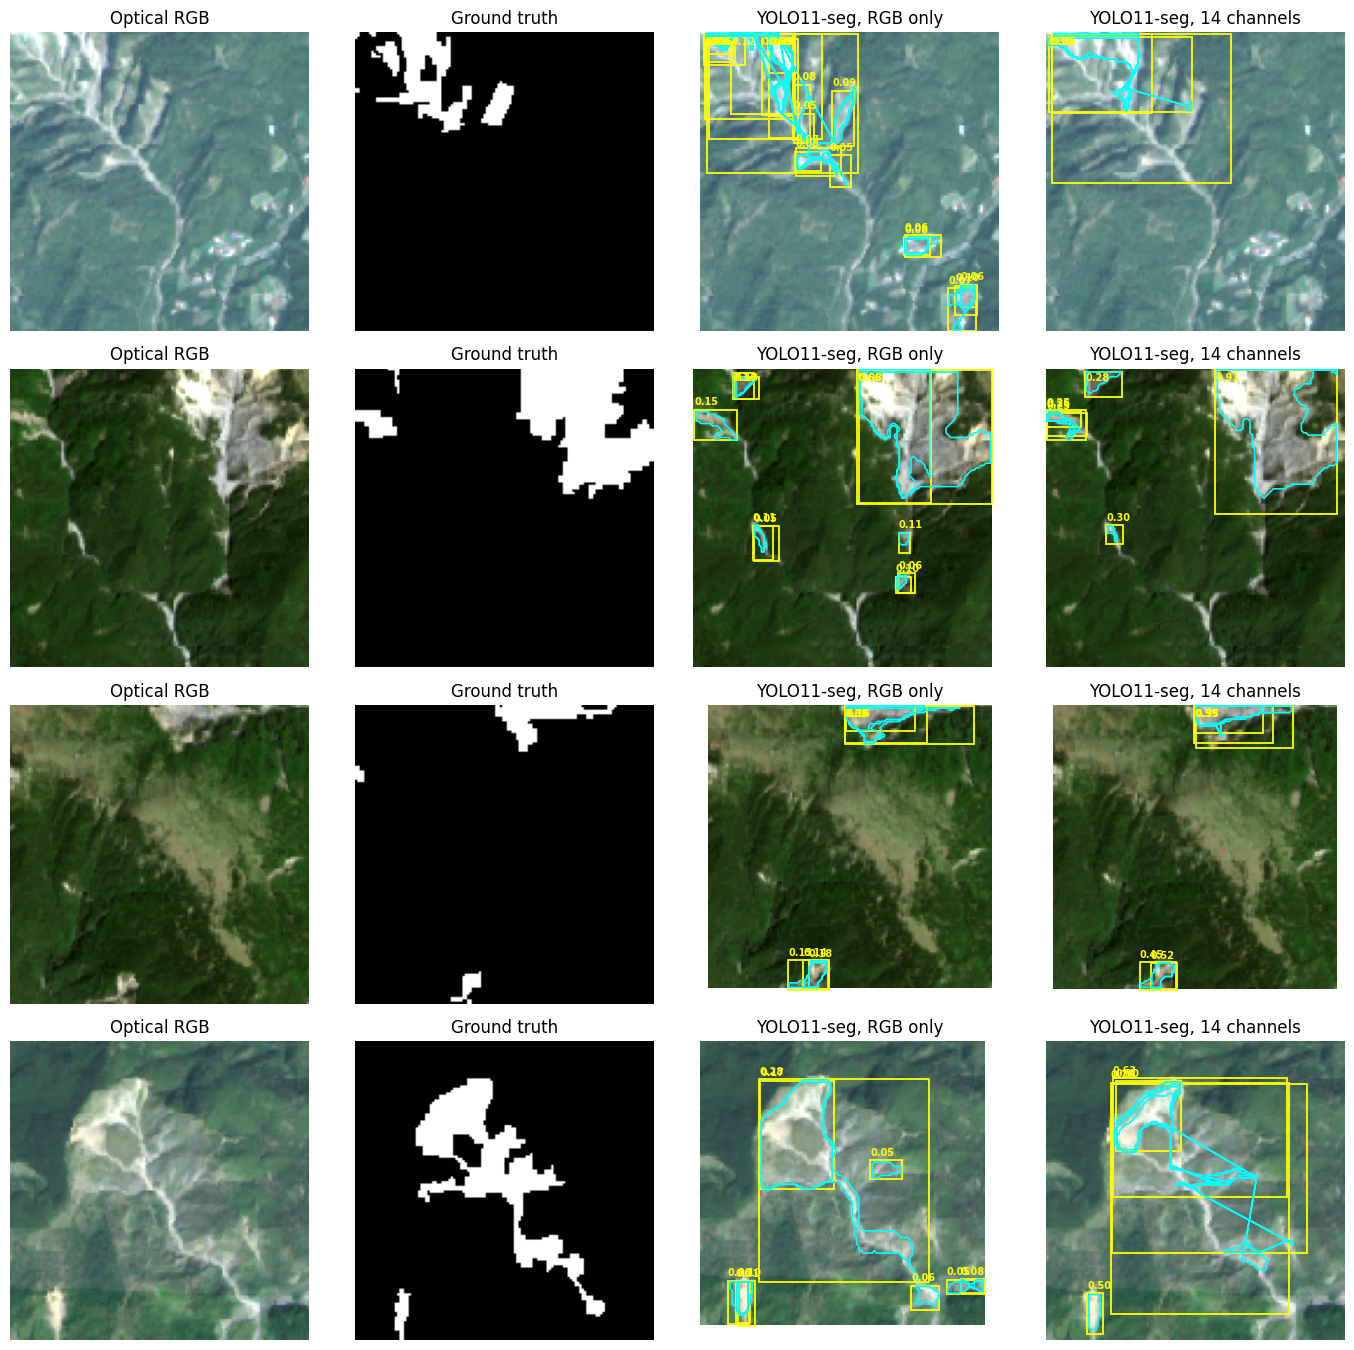

In [ ]:
seed0 = SEEDS[0]
names_t, cache_rgb, thr_rgb = caches[('rgb', seed0)]
_, cache_14, thr_14 = caches[('ch14', seed0)]
gts = load_gts('test', names_t)
sel = [i for i, g in enumerate(gts) if g.sum() >= 300][:4]

def draw(ax, item, thr, color_box='yellow', color_poly='cyan'):
    for poly, sc, bx in zip(item['polys'], item['scores'], item['boxes']):
        if sc < thr: continue
        ax.add_patch(plt.Rectangle((bx[0], bx[1]), bx[2] - bx[0], bx[3] - bx[1], fill=False, edgecolor=color_box, linewidth=1.3))
        p = np.vstack([poly, poly[:1]])
        ax.plot(p[:, 0], p[:, 1], color=color_poly, linewidth=1.2)
        ax.text(bx[0], max(bx[1] - 2, 5), f"{sc:.2f}", color=color_box, fontsize=7, fontweight='bold')

fig, ax = plt.subplots(len(sel), 4, figsize=(14, 3.4 * len(sel)))
for r, i in enumerate(sel):
    rgbimg = read_tiff_like_ultralytics(f'{ROOT}/ch14/images/test/{names_t[i]}.tiff')[:, :, [3, 2, 1]]
    ax[r, 0].imshow(rgbimg); ax[r, 0].set_title("Optical RGB")
    ax[r, 1].imshow(gts[i], cmap='gray'); ax[r, 1].set_title("Ground truth")
    ax[r, 2].imshow(rgbimg); draw(ax[r, 2], cache_rgb[i], thr_rgb); ax[r, 2].set_title("YOLO11-seg, RGB only")
    ax[r, 3].imshow(rgbimg); draw(ax[r, 3], cache_14[i], thr_14); ax[r, 3].set_title("YOLO11-seg, 14 channels")
    for a in ax[r]: a.axis('off')
plt.tight_layout(); plt.savefig(f'{OUT}/phase6_yolo_objects.png', dpi=150); plt.show()